# 13 – Results in Charts

**Objective:** show the final test results from notebook 08 and the event study from notebook 09 in charts for the README.

**Key results**
- **Beats the ranking on every surface:** on the same 10,375 matches, the model is 2.4 to 4.1 points above picking the best-ranked player.
- **Pinnacle stays ahead everywhere:** it is 1.0 to 1.4 points above the model on each surface.
- **Probabilities can be trusted:** in every calibration group, the favourites' real win rate is within 2.4 points of the prediction.
- **Rank gaps matter most:** accuracy goes from 60.1% between two players ranked 51–100, to 84.7% when a top 10 player meets someone outside the top 100.
- **Players win less after retiring:** in the next match, win probability is 5.49 points lower than after an ordinary loss (95% interval: −6.71 to −4.22). This isn't proof of a causal effect of injury.

**Rule:** these charts only describe results. Nothing here changes the model, because adjusting it after looking at the test matches would make the test no longer clean.


In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../src")
from tennis_data import load_all_matches
from tennis_domain_features import DOMAIN_GROUPS
from tennis_elo import run_elo
from tennis_event_study import build_windows, estimate_path, player_match_table, pooled_effect, walkover_losses_by_player
from tennis_features import FEATURE_GROUPS
from tennis_models import INTERACTIONS, add_interactions, logistic_model, score, walk_forward
from tennis_odds import link_odds, load_odds

TEXT_COLOR = "#52514e"
TITLE_COLOR = "#0b0b0b"
GRID_COLOR = "#e4e3df"
REFERENCE_COLOR = "#8a8981"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
TEST_YEARS = range(2022, 2027)
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)


def tidy(ax, title, grid="y"):
    """The same quiet axes on every chart."""
    ax.set_title(title, loc="left", fontsize=12, color=TITLE_COLOR)
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.grid(axis=grid, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_COLOR, length=0)


def save(fig, name):
    fig.savefig(IMAGES / name, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()


conn = sqlite3.connect(Path("../data/processed/tennis.db"))
data = pd.read_sql_query("SELECT * FROM final_features WHERE tourney_level <> 'D'", conn)
data = add_interactions(data)
test = data["year"].isin(TEST_YEARS)

ORDER = ["Elo", "Ranking", "Serve and return", "Form", "Fatigue and fitness", "Experience",
         "Style and age", "Head to head", "Draw", "Home"]
FINAL_COLUMNS = (
    [c for group in ORDER for c in FEATURE_GROUPS[group]]
    + list(INTERACTIONS) + DOMAIN_GROUPS["Tournament history"]
)
print(f"{test.sum():,} test matches, {len(FINAL_COLUMNS)} model columns")

12,215 test matches, 60 model columns


## 1. The same predictions as notebook 08

The code below repeats the walk-forward predictions and stops with an error if any total differs from notebook 08.

In [2]:
model_p = walk_forward(data, FINAL_COLUMNS, logistic_model, years=TEST_YEARS)
rank_p = walk_forward(data, ["d_log_rank"], logistic_model, years=TEST_YEARS)

details = pd.read_sql_query("""
SELECT m.tourney_id, m.match_num, m.round, m.winner_rank, m.loser_rank,
       t.tourney_name, t.tourney_date, t.surface,
       w.name_first AS winner_first, w.name_last AS winner_surname,
       l.name_first AS loser_first, l.name_last AS loser_surname
FROM matches AS m
JOIN tournaments AS t ON m.tourney_id = t.tourney_id
JOIN players AS w ON m.winner_id = w.player_id
JOIN players AS l ON m.loser_id = l.player_id
""", conn)

matches = data.loc[test, ["tourney_id", "match_num", "year", "tourney_level", "d_elo_combined"]].copy()
matches["model_p"] = model_p[test]
matches["rank_p"] = rank_p[test]
matches = matches.merge(details, on=["tourney_id", "match_num"], validate="one_to_one")
matches["start_date"] = pd.to_datetime(matches["tourney_date"])

# The numbers must match notebook 08 before anything is drawn
assert score(matches["model_p"]) == {"accuracy_pct": 66.98, "log_loss": 0.5929}
assert score(matches["rank_p"]) == {"accuracy_pct": 63.81, "log_loss": 0.631}

odds = load_odds("../data/raw/odds", first_year=2022)
matches["odds_row"] = link_odds(matches, odds)
linked = matches.dropna(subset=["odds_row"]).join(odds, on="odds_row")
pinnacle = linked[(linked["year"] <= 2025) & linked["PSW"].notna() & linked["PSL"].notna()].copy()
pinnacle["pinnacle_p"] = (1 / pinnacle["PSW"]) / (1 / pinnacle["PSW"] + 1 / pinnacle["PSL"])

assert len(pinnacle) == 10375
assert score(pinnacle["model_p"]) == {"accuracy_pct": 66.57, "log_loss": 0.5959}
assert score(pinnacle["pinnacle_p"]) == {"accuracy_pct": 67.71, "log_loss": 0.5889}
print("All totals match notebook 08.")

All totals match notebook 08.


## 2. Accuracy by surface

All three methods are scored on the same matches, the ones with Pinnacle odds. The intervals are only a guide to how much each score could vary by luck, and they treat each method separately.

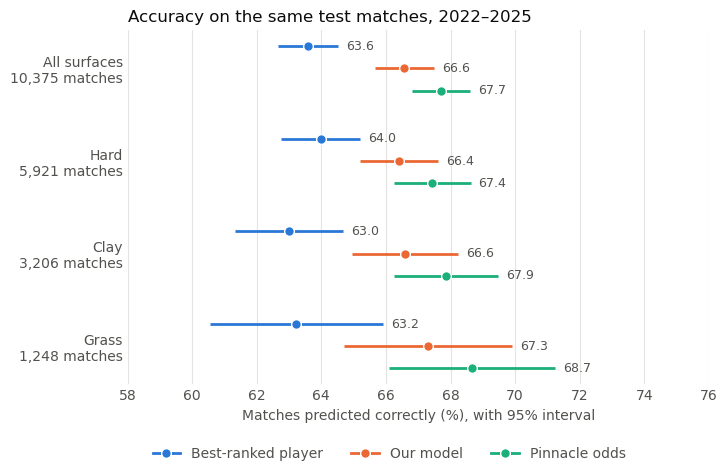

,group,n_matches,method,accuracy_pct,margin_95
0,All surfaces,10375,Best-ranked player,63.59,0.93
1,All surfaces,10375,Our model,66.57,0.91
2,All surfaces,10375,Pinnacle odds,67.71,0.90
3,Hard,5921,Best-ranked player,63.98,1.22
4,Hard,5921,Our model,66.41,1.20
5,Hard,5921,Pinnacle odds,67.43,1.19
6,Clay,3206,Best-ranked player,63.01,1.67
7,Clay,3206,Our model,66.59,1.63
8,Clay,3206,Pinnacle odds,67.86,1.62
9,Grass,1248,Best-ranked player,63.22,2.68


In [3]:
METHODS = {"Best-ranked player": "rank_p", "Our model": "model_p", "Pinnacle odds": "pinnacle_p"}
groups = {"All surfaces": pinnacle, **{s: pinnacle[pinnacle["surface"] == s] for s in ["Hard", "Clay", "Grass"]}}

rows = []
for group, frame in groups.items():
    for method, column in METHODS.items():
        accuracy = score(frame[column])["accuracy_pct"]
        margin = 196 * np.sqrt(accuracy / 100 * (1 - accuracy / 100) / len(frame))
        rows.append({"group": group, "n_matches": len(frame), "method": method, "accuracy_pct": accuracy, "margin_95": round(margin, 2)})
by_surface = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for g, (group, frame) in enumerate(by_surface.groupby("group", sort=False)):
    for m, row in enumerate(frame.itertuples()):
        y = g + (m - 1) * 0.24
        ax.errorbar(row.accuracy_pct, y, xerr=row.margin_95, color=COLORS[m], marker="o", markersize=7,
                    markeredgecolor="white", linewidth=2, label=row.method if g == 0 else None)
        ax.text(row.accuracy_pct + row.margin_95 + 0.25, y, f"{row.accuracy_pct:.1f}", va="center", fontsize=9, color=TEXT_COLOR)
sizes = by_surface.drop_duplicates("group")
ax.set_yticks(range(len(sizes)), [f"{r.group}\n{r.n_matches:,} matches" for r in sizes.itertuples()], color=TEXT_COLOR)
ax.invert_yaxis()
ax.set_xlim(58, 76)
ax.set_xlabel("Matches predicted correctly (%), with 95% interval", color=TEXT_COLOR)
tidy(ax, "Accuracy on the same test matches, 2022–2025", grid="x")
ax.legend(frameon=False, labelcolor=TEXT_COLOR, ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.14))
save(fig, "accuracy_by_surface.png")
by_surface

## 3. Calibration

A calibrated model means what it says: of the favourites given about 70%, about 70% should win. Each point is one group of matches, and the dashed line is perfect calibration.

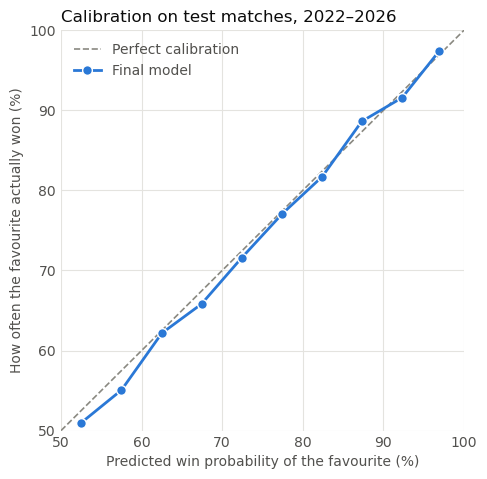

,n_matches,predicted,actual
0,1949,0.525,0.509
1,1969,0.575,0.551
2,1792,0.625,0.622
3,1594,0.674,0.658
4,1406,0.724,0.716
5,1231,0.775,0.771
6,902,0.824,0.817
7,676,0.873,0.886
8,463,0.923,0.916
9,233,0.969,0.974


In [4]:
p = matches["model_p"]
table = pd.DataFrame({"predicted": np.maximum(p, 1 - p), "won": p > 0.5})
table["bucket"] = pd.cut(table["predicted"], np.arange(0.5, 1.01, 0.05), include_lowest=True)
calibration = (
    table.groupby("bucket", observed=True)
    .agg(n_matches=("won", "size"), predicted=("predicted", "mean"), actual=("won", "mean"))
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([50, 100], [50, 100], color=REFERENCE_COLOR, linestyle="--", linewidth=1.2, label="Perfect calibration")
ax.plot(100 * calibration["predicted"], 100 * calibration["actual"], color=COLORS[0],
        linewidth=2, marker="o", markersize=7, markeredgecolor="white", label="Final model")
ax.set_xlim(50, 100)
ax.set_ylim(50, 100)
ax.set_xlabel("Predicted win probability of the favourite (%)", color=TEXT_COLOR)
ax.set_ylabel("How often the favourite actually won (%)", color=TEXT_COLOR)
tidy(ax, "Calibration on test matches, 2022–2026", grid="both")
ax.legend(frameon=False, labelcolor=TEXT_COLOR, loc="upper left")
save(fig, "calibration.png")
calibration.round(3)

## 4. Accuracy by rank

Each match goes in one cell, using the ranks of its higher- and lower-ranked player. The code stops if a cell has fewer than 100 matches, because a tiny sample can give a misleading number such as 100%.

Without a rank for both players: 28 of 12,215 matches


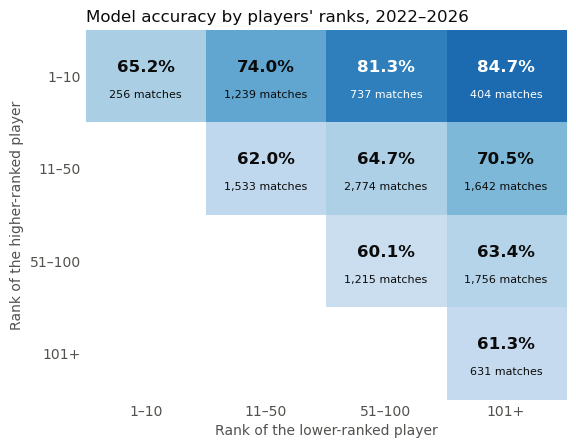

,better,worse,n_matches,accuracy
0,1–10,1–10,256,0.652
1,1–10,11–50,1239,0.740
2,1–10,51–100,737,0.813
3,1–10,101+,404,0.847
4,11–50,11–50,1533,0.620
5,11–50,51–100,2774,0.647
6,11–50,101+,1642,0.705
7,51–100,51–100,1215,0.601
8,51–100,101+,1756,0.634
9,101+,101+,631,0.613


In [5]:
BANDS = [0, 10, 50, 100, np.inf]
LABELS = ["1–10", "11–50", "51–100", "101+"]

ranked = matches.dropna(subset=["winner_rank", "loser_rank"]).copy()
print(f"Without a rank for both players: {len(matches) - len(ranked):,} of {len(matches):,} matches")
ranked["better"] = pd.cut(ranked[["winner_rank", "loser_rank"]].min(axis=1), BANDS, labels=LABELS)
ranked["worse"] = pd.cut(ranked[["winner_rank", "loser_rank"]].max(axis=1), BANDS, labels=LABELS)
ranked["correct"] = np.where(ranked["model_p"] == 0.5, 0.5, ranked["model_p"] > 0.5)

cells = ranked.groupby(["better", "worse"], observed=True)["correct"].agg(n_matches="size", accuracy="mean").reset_index()
accuracy = cells.pivot(index="better", columns="worse", values="accuracy").reindex(index=LABELS, columns=LABELS)
counts = cells.pivot(index="better", columns="worse", values="n_matches").reindex(index=LABELS, columns=LABELS)
shown = accuracy * 100
assert counts.stack().min() >= 100  # No score below comes from a tiny sample

fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.imshow(shown, cmap="Blues", vmin=50, vmax=95, aspect="auto")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        value = shown.iat[i, j]
        if pd.isna(value):
            continue
        color = "white" if value >= 75 else TITLE_COLOR
        ax.text(j, i - 0.1, f"{value:.1f}%", ha="center", va="center", fontsize=12, fontweight="bold", color=color)
        ax.text(j, i + 0.2, f"{int(counts.iat[i, j]):,} matches", ha="center", va="center", fontsize=8, color=color)
ax.set_xticks(range(4), LABELS, color=TEXT_COLOR)
ax.set_yticks(range(4), LABELS, color=TEXT_COLOR)
ax.set_xlabel("Rank of the lower-ranked player", color=TEXT_COLOR)
ax.set_ylabel("Rank of the higher-ranked player", color=TEXT_COLOR)
tidy(ax, "Model accuracy by players' ranks, 2022–2026", grid="both")
ax.grid(False)
save(fig, "accuracy_by_rank.png")
cells.round(3)

## 5. Elo over time

This chart uses all matches in the main database, not only the test years. Each line is the last pre-match Elo rating of each quarter. The newer TennisMyLife matches are not included, so the chart stops in June 2026. A line below 1900 is cut off, which hides the first years of each career.

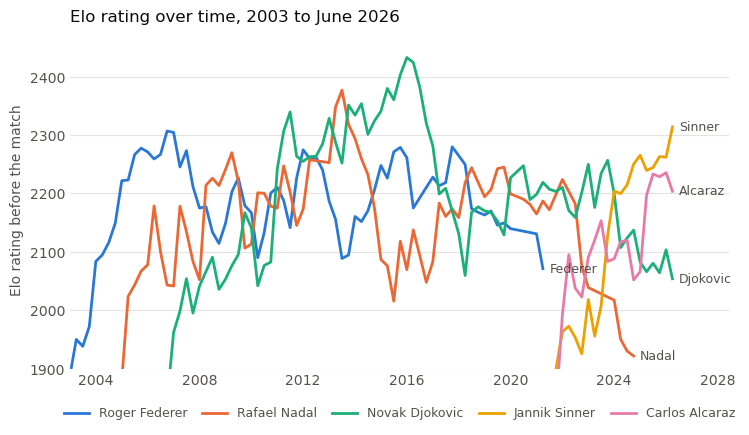

,player,peak_elo,peak_quarter,last_elo,last_quarter
0,Roger Federer,2307,2006Q4,2071,2021Q2
1,Rafael Nadal,2377,2013Q3,1922,2024Q4
2,Novak Djokovic,2433,2016Q1,2054,2026Q2
3,Jannik Sinner,2314,2026Q2,2314,2026Q2
4,Carlos Alcaraz,2236,2026Q1,2204,2026Q2


In [6]:
PLAYERS = {"Roger Federer": 103819, "Rafael Nadal": 104745, "Novak Djokovic": 104925,
           "Jannik Sinner": 206173, "Carlos Alcaraz": 207989}
ratings = pd.read_sql_query("""
SELECT t.tourney_date, m.match_num, m.winner_id, m.loser_id, e.winner_elo, e.loser_elo
FROM elo_ratings AS e
JOIN matches AS m ON e.tourney_id = m.tourney_id AND e.match_num = m.match_num
JOIN tournaments AS t ON e.tourney_id = t.tourney_id
""", conn, parse_dates=["tourney_date"])
long = pd.concat([
    ratings[["tourney_date", "match_num", "winner_id", "winner_elo"]].set_axis(["date", "match_num", "player", "elo"], axis=1),
    ratings[["tourney_date", "match_num", "loser_id", "loser_elo"]].set_axis(["date", "match_num", "player", "elo"], axis=1),
]).sort_values(["date", "match_num"], kind="stable")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
peaks = []
for color, (name, player) in zip(COLORS, PLAYERS.items()):
    # Last rating of each quarter, so a single tournament doesn't hide the trend
    line = long[long["player"] == player].set_index("date")["elo"].resample("QS").last().dropna()
    ax.plot(line.index, line, color=color, linewidth=2, label=name)
    ax.text(line.index[-1] + pd.Timedelta(days=90), line.iloc[-1], name.split()[-1], va="center", fontsize=9, color=TEXT_COLOR)
    peaks.append({"player": name, "peak_elo": round(line.max()), "peak_quarter": str(line.idxmax().to_period("Q")),
                  "last_elo": round(line.iloc[-1]), "last_quarter": str(line.index[-1].to_period("Q"))})
ax.set_ylim(1900, 2480)
ax.set_xlim(pd.Timestamp("2003-01-01"), pd.Timestamp("2028-06-01"))
ax.set_ylabel("Elo rating before the match", color=TEXT_COLOR)
tidy(ax, "Elo rating over time, 2003 to June 2026")
ax.legend(frameon=False, labelcolor=TEXT_COLOR, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9, columnspacing=1.2)
save(fig, "elo_over_time.png")
pd.DataFrame(peaks)

## 6. Event study of retirements

This repeats the corrected comparison from notebook 09, which uses matches from 2005 to 2021. Each point compares a player's results around a retirement with the same player's ordinary losses. Points before the retirement should stay near zero, and the shaded area is the baseline.

In [7]:
# Only matches up to 2021, as in notebook 09, so the test years stay out of this study
LAST_YEAR = 2021
study_matches = load_all_matches("../data/raw")
study_matches = study_matches[study_matches["year"] <= LAST_YEAR].reset_index(drop=True)
study_ratings = run_elo(study_matches, k=28, inactivity=0.3, new_player_boost=1.0)
long = player_match_table(study_matches, study_ratings)
windows, events = build_windows(long, walkover_losses_by_player(study_matches), match_position=True)
table, draws = estimate_path(windows)

# The numbers must match notebook 09 before anything is drawn
first = pooled_effect(table, draws, [1])
pretrend = pooled_effect(table, draws, range(-5, 0))
assert (events["group"] == 1).sum() == 8032
assert [round(first[c], 2) for c in ["effect", "low_95", "high_95"]] == [-5.49, -6.71, -4.22]
assert [round(pretrend[c], 2) for c in ["effect", "low_95", "high_95"]] == [0.31, -0.39, 1.03]
print("All totals match notebook 09.")

All totals match notebook 09.


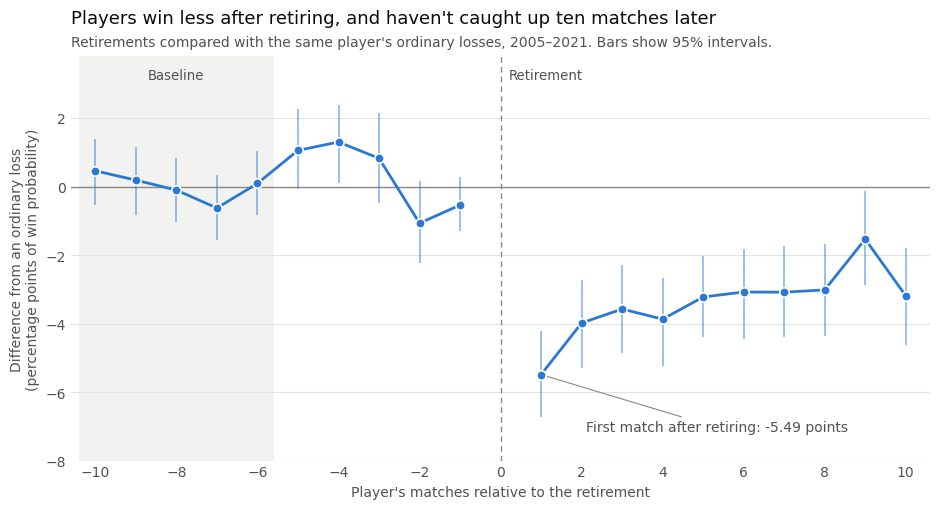

In [8]:
CHART_COLOR = COLORS[0]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.axvspan(-10.4, -5.6, color=GRID_COLOR, alpha=0.45, linewidth=0, zorder=0)
ax.axhline(0, color=REFERENCE_COLOR, linewidth=1, zorder=1)
ax.axvline(0, color=REFERENCE_COLOR, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
for part in [table[table["k"] < 0], table[table["k"] > 0]]:
    ax.plot(part["k"], part["effect"], color=CHART_COLOR, linewidth=2, zorder=3)
ax.vlines(table["k"], table["low_95"], table["high_95"], color=CHART_COLOR, linewidth=1.2, alpha=0.55, zorder=2)
ax.scatter(table["k"], table["effect"], s=46, color=CHART_COLOR, edgecolor="white", linewidth=1.2, zorder=4)

first_match = table[table["k"] == 1].iloc[0]
ax.annotate(f"First match after retiring: {first_match['effect']:.2f} points", xy=(1, first_match["effect"]),
            xytext=(2.1, -7.15), color=TEXT_COLOR, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=REFERENCE_COLOR, linewidth=0.8))
ax.text(-8, 3.25, "Baseline", color=TEXT_COLOR, fontsize=9.5, ha="center", va="center")
ax.text(0.2, 3.25, "Retirement", color=TEXT_COLOR, fontsize=9.5, ha="left", va="center")

ax.set_xlim(-10.6, 10.6)
ax.set_ylim(-8, 3.8)
ax.set_xticks(range(-10, 11, 2))
ax.set_yticks(range(-8, 4, 2))
ax.set_xlabel("Player's matches relative to the retirement", color=TEXT_COLOR)
ax.set_ylabel("Difference from an ordinary loss\n(percentage points of win probability)", color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR, length=0)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.set_title("Players win less after retiring, and haven't caught up ten matches later",
             loc="left", fontsize=13, color="#0b0b0b", pad=24)
ax.text(0, 1.025, "Retirements compared with the same player's ordinary losses, 2005–2021. Bars show 95% intervals.",
        transform=ax.transAxes, color=TEXT_COLOR, fontsize=10)
fig.tight_layout()
save(fig, "event_study_retirements.png")

## 7. Conclusions

| Question | Answer |
|---|---|
| Is the model better than the ranking? | Yes, on each surface, by 2.4 points on hard, 3.6 on clay and 4.1 on grass |
| Is it better than the market? | No, Pinnacle is ahead on each surface |
| Does a surface suit the model best? | Not shown: its scores on hard, clay and grass are within 1 point, and their intervals overlap |
| Are its probabilities reliable? | Mostly: the largest gap is 2.4 points, and close matches are slightly overconfident |
| Where is it strongest? | When the rank gap is large, which is also when the result is easiest to predict |
| Do players win less after retiring? | Yes, compared with ordinary losses, but this doesn't prove that injuries cause the drop |

**Limits**
- **High accuracy isn't always skill:** a top 10 player against someone outside the top 100 is an easy match to call. This chart doesn't show how much the model adds in each cell compared with the ranking.
- **Intervals are approximate:** they treat each method separately, and the three methods are scored on the same matches, so they can't be used as a formal test of the gap between two methods.
- **Period:** the surface chart stops in 2025, because Pinnacle's odds are nearly absent from 2026. The ranking scores 63.59% on these matches and 63.81% on the full test.
